In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('train.csv', usecols=['GarageQual', 'FireplaceQu', 'SalePrice'])

In [3]:
df.head()
# here saleprice is the categorical value so it is a REGRESSION PROBLEM

,FireplaceQu,GarageQual,SalePrice
0,NaN,TA,208500
1,TA,TA,181500
2,TA,TA,223500
3,Gd,TA,140000
4,TA,TA,250000


In [4]:
df.isnull().sum()

FireplaceQu    690
GarageQual      81
SalePrice        0
dtype: int64

In [5]:
df.isnull().mean()*100

FireplaceQu    47.260274
GarageQual      5.547945
SalePrice       0.000000
dtype: float64

<Axes: xlabel='GarageQual'>

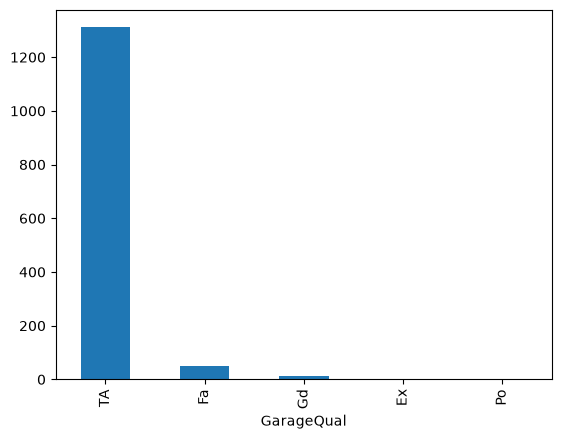

In [6]:
df['GarageQual'].value_counts().plot(kind='bar')

In [8]:
df['GarageQual'].mode() # TA repeacts the most form o/p

0    TA
Name: GarageQual, dtype: str

df['GarageQual'] == 'TA' → finds rows where GarageQual is TA

df[...] → keeps only those rows

['SalePrice'] → takes only the SalePrice column

.plot(kind='kde') → draws a KDE curve showing how the SalePrice values are distributed
ax=ax → draws the curve on the existing graph/axis called ax

So basically:

“Take the SalePrice of houses whose GarageQual is TA and draw their price distribution as a KDE curve.”

Text(0.5, 1.0, 'GarageQual')

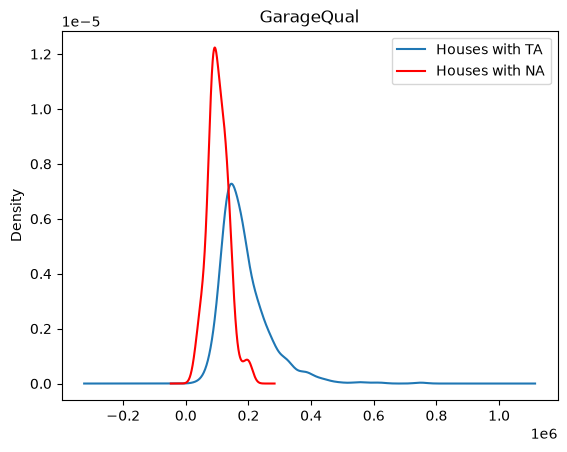

In [16]:
fig = plt.figure()
ax = fig.add_subplot(111)

df[df['GarageQual'] =='TA'] ['SalePrice'].plot(kind='kde', ax=ax) # 
df[df['GarageQual'].isnull()]['SalePrice'].plot(kind='kde', ax=ax, color='red') # finding missing values in garageQual column

lines,labels = ax.get_legend_handles_labels()
labels = ['Houses with TA', 'Houses with NA']
ax.legend(lines, labels, loc='best')

plt.title('GarageQual')

In [20]:
temp = df[df['GarageQual']=='TA']['SalePrice'] # just storing TA value (blue curve data) in variable

In [23]:
df['GarageQual'] = df['GarageQual'].fillna('TA') # replacing missing values with TA

<Axes: xlabel='GarageQual'>

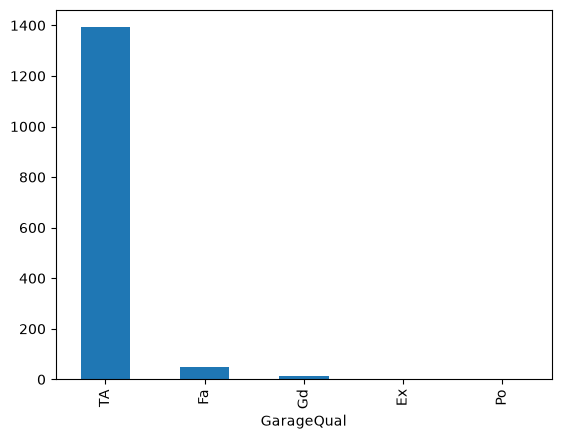

In [24]:
df['GarageQual'].value_counts().plot(kind='bar')

Text(0.5, 1.0, 'GarageQual')

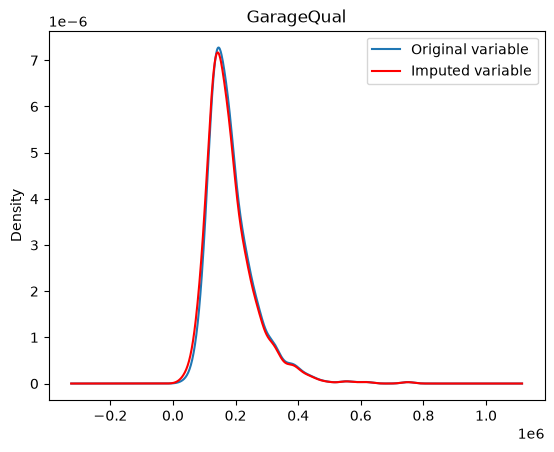

In [28]:
fig = plt.figure()
ax = fig.add_subplot(111)

# distribution of the varibale before imputtaion stroe in variable temp
temp.plot(kind='kde', ax=ax)

# distribution of the variable after imputation
df[df['GarageQual'] == 'TA']['SalePrice'].plot(kind='kde', ax=ax, color='red')

lines, labels = ax.get_legend_handles_labels()
labels = ['Original variable', 'Imputed variable']
ax.legend(lines, labels, loc='best')

# add title
plt.title('GarageQual')

# HERE YOU WONT FIND MUCH DIFFERENECE BECAUSE THERE WERE LESS MISSING VALUE

<Axes: xlabel='FireplaceQu'>

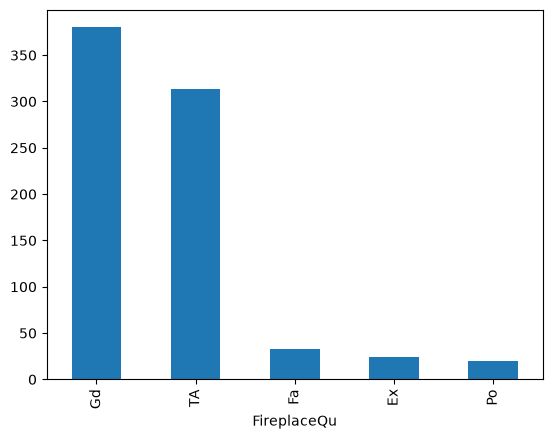

In [31]:
df['FireplaceQu'].value_counts().plot(kind='bar')
# here the reulst wont come nice because the diffence in most repeacted value should be large but here that's not the case

In [32]:
df['FireplaceQu'].mode() 

0    Gd
Name: FireplaceQu, dtype: str

Text(0.5, 1.0, 'FireplaceQu')

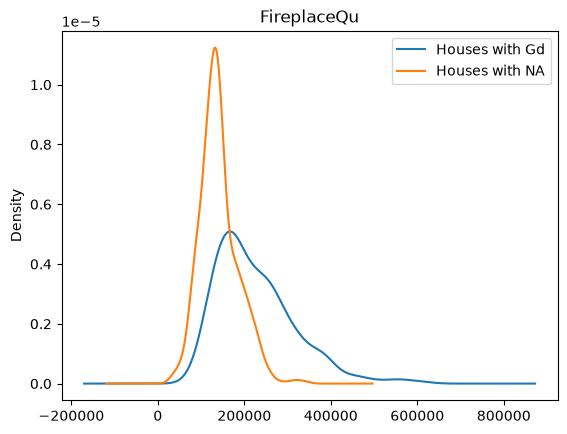

In [35]:
fig = plt.figure()
ax = fig.add_subplot(111)

df[df['FireplaceQu'] == 'Gd']['SalePrice'].plot(kind='kde', ax=ax)

df[df['FireplaceQu'].isnull()] ['SalePrice'].plot(kind='kde', ax=ax)

lines, labels = ax.get_legend_handles_labels()
labels = ['Houses with Gd', 'Houses with NA']
ax.legend(lines, labels, loc= 'best')

plt.title('FireplaceQu')

In [36]:
temp = df[df['FireplaceQu'] == 'Gd'] ['SalePrice']

In [37]:
df['FireplaceQu'] = df['FireplaceQu'].fillna('Gd') # replacing missing values with Gd

<Axes: xlabel='FireplaceQu'>

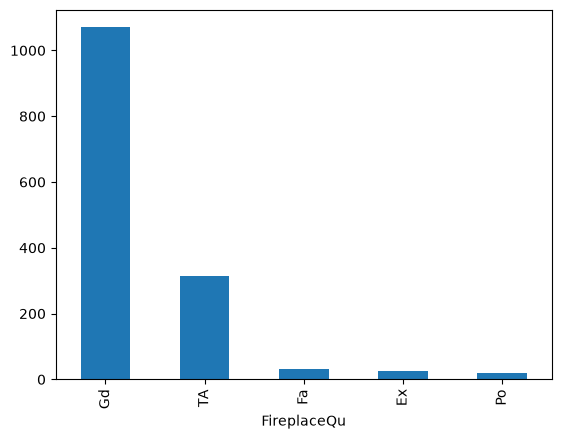

In [38]:
df['FireplaceQu'].value_counts().plot(kind='bar')

Text(0.5, 1.0, 'FireplaceQu')

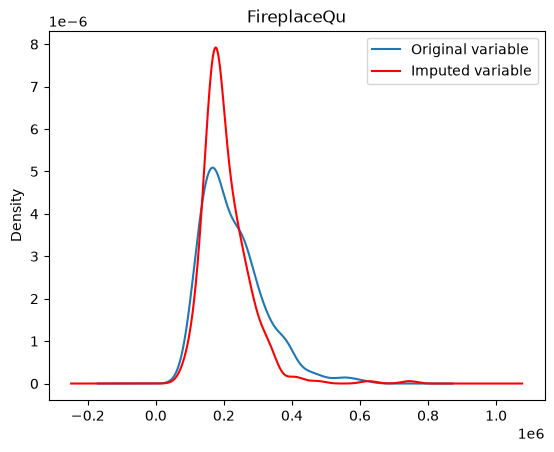

In [39]:
fig = plt.figure()
ax = fig.add_subplot(111)

# distribution of the varibale before imputtaion stroe in variable temp
temp.plot(kind='kde', ax=ax)

# distribution of the variable after imputation
df[df['FireplaceQu'] == 'TA']['SalePrice'].plot(kind='kde', ax=ax, color='red')

lines, labels = ax.get_legend_handles_labels()
labels = ['Original variable', 'Imputed variable']
ax.legend(lines, labels, loc='best')

# add title
plt.title('FireplaceQu')

# HERE YOU  FIND MUCH DIFFERENECE BECAUSE THERE WERE MORE  MISSING VALUE RED FLAG ****

In [40]:
from sklearn.model_selection import train_test_split

In [43]:
X_train, X_test, y_train, y_test = train_test_split(df.drop(columns=['SalePrice']), df['SalePrice'], test_size=0.2)

In [44]:
from sklearn.impute import SimpleImputer

In [46]:
imputer = SimpleImputer(strategy = 'most_frequent')

In [47]:
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

In [49]:
imputer.statistics_ # from o/p we know gd is the most frequent category in column 1 and ta is the most frequent in column 2

array(['Gd', 'TA'], dtype=object)